# ２章　マルコフ決定過程
## 『ゼロから作る Deep Learning ❹』2.1〜2.2 輪読会

第 1 章のバンディットから、行動によって次の状況が変わる<strong>マルコフ決定過程（MDP）</strong>へ進む。今回は、状態・行動・報酬を区別し、環境を表す状態遷移と報酬関数、エージェントを表す方策を理解する。

数式は図の具体例と対応させて読む。将来の報酬をまとめる「収益」や、最適方策の定義は次の 2.3 で扱う。

### 目次

| 節 | 要点 |
|---|---|
| 2.1.1〜2.1.2 | MDP の具体例と、状態・行動・報酬のやりとり |
| 2.2.1 | 状態遷移、マルコフ性、確率的な移動 |
| 2.2.2 | 報酬関数と、1 ステップの期待報酬 |
| 2.2.3 | 方策と、環境の確率との違い |
| 振り返り | まとめと確認問題 3 問 |

節の対応は[出版社の目次](https://www.oreilly.co.jp/books/9784873119755/)、本編の盤面は [`common/gridworld.py`](../common/gridworld.py) を参照する。図と追加実験は輪読用に構成した。

## 0. 実行環境

NumPy と Matplotlib を使い、セルを上から順に実行する。リポジトリのルートで次を実行すると JupyterLab を起動できる。

```bash
uv run --extra notebooks jupyter lab my_notebooks
```

図の文字は日本語フォントに依存しない英語表記とする。図を描くコードは折り畳んであり、必要に応じて開ける。他の Notebook の実行結果や外部データは使わない。

In [13]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

COLORS = ["#137C83", "#D97732", "#7455A4", "#456A9C"]
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
    # Notebook の表示幅でも、目盛りや添字が読みやすいサイズにする。
    "axes.grid": True, "grid.alpha": 0.18, "font.size": 20,
    "axes.titlesize": 22, "axes.titlepad": 18, "axes.labelsize": 20,
    "xtick.labelsize": 20, "ytick.labelsize": 20, "legend.fontsize": 18,
    "axes.prop_cycle": matplotlib.cycler(color=COLORS),
})
print("Python", sys.version.split()[0])
print("NumPy", np.__version__, "Matplotlib", matplotlib.__version__)

Python 3.11.15
NumPy 1.23.5 Matplotlib 3.10.9


### 記号の読み方

| 記号 | 意味 |
|---|---|
| $S_t$、$s$ | 時刻 $t$ の状態を表す確率変数と、その具体的な値 |
| $A_t$、$a$ | 選ぶ行動と、その具体的な値 |
| $R_t$、$r_t$ | 行動 $A_t$ の結果として得る報酬と、その実現値 |
| $S_{t+1}$、$s'$ | 行動後の次状態。プライムは微分ではない |

この資料は $S_t \rightarrow A_t \rightarrow (R_t,S_{t+1})$ の順で表す。結果の報酬を $R_{t+1}$ と書く文献もあるが、ここでは $R_t$ に統一する。観測した数値 $r_t$ と、後で定義する報酬関数 $r(s,a,s')$ は別のものである。

# 2.1 MDPとは
## 2.1.1 MDPの具体例

バンディットでは、腕を選んで報酬を受け取り、次も同じ腕から選ぶ。MDP では<strong>行動が次の状態を変え、その先の行動の結果にも影響する</strong>。

図 1 の上段はバンディット、下段は説明用の 1 行 × 3 マスのグリッドワールドである。下段の 3 つは別の環境ではなく、同じ盤面の時刻ごとの様子を示す。青緑の丸が現在位置、右端の緑のマスがゴールである。

位置 0 から `RIGHT` を選ぶと位置 1 に移って報酬 0、次の `RIGHT` でゴールの 2 に移って $+1$ を得る。同じ行動でも、状態によって結果が変わる。

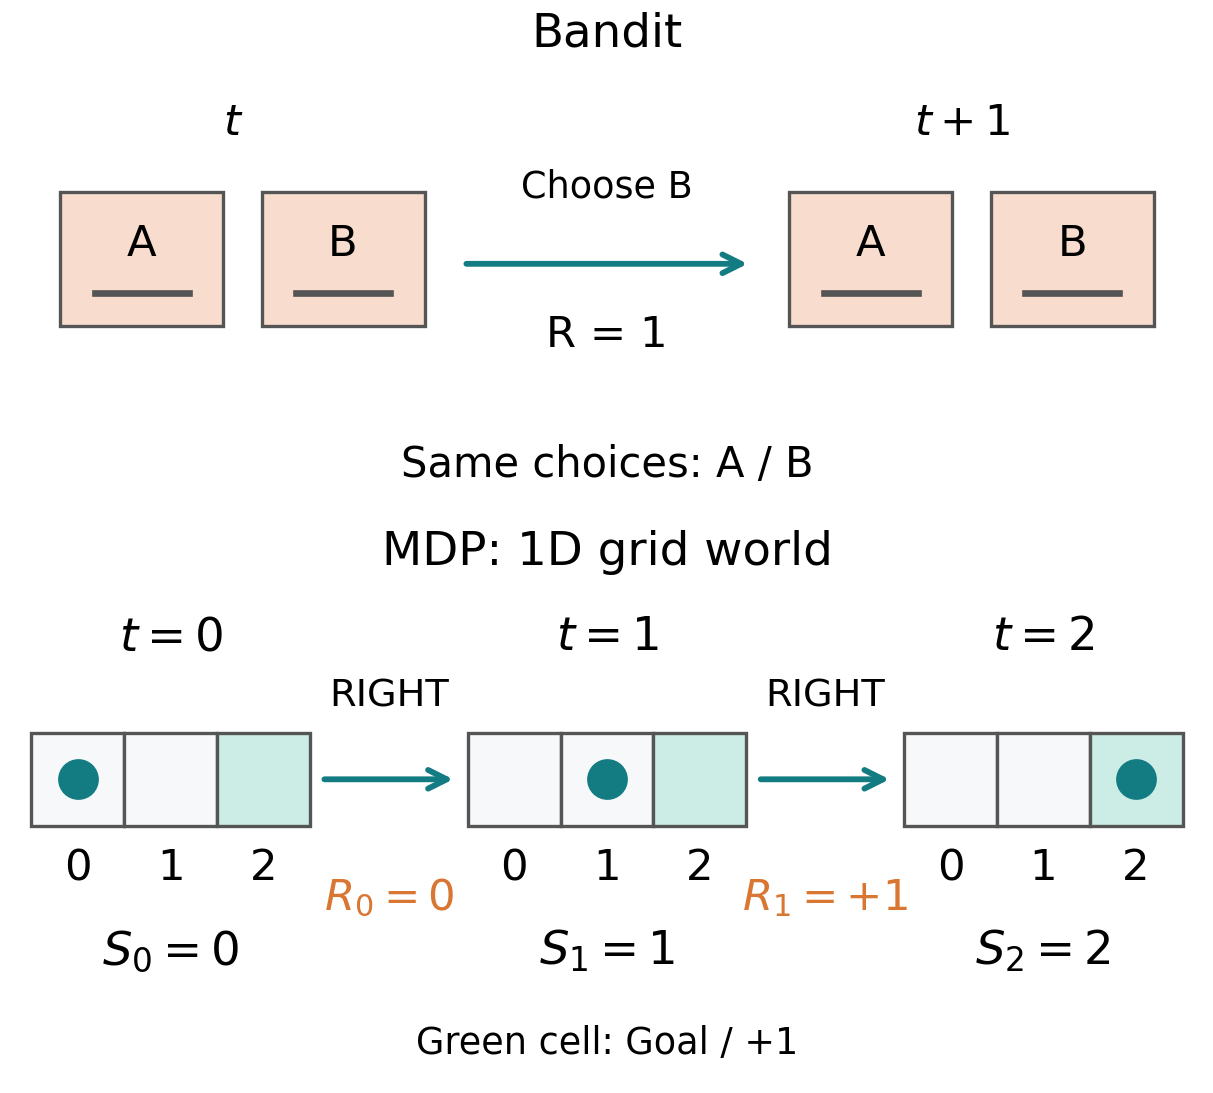

In [14]:
# 説明図に共通の、箱と矢印。長い説明は図の下の文章に置く。
def concept_box(ax, center, text, width=2.4, height=1.0,
                color="#f7f8fa", fontsize=26):
    x, y = center
    ax.add_patch(Rectangle((x - width / 2, y - height / 2), width, height,
                           facecolor=color, edgecolor="#555555", linewidth=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize)

def concept_arrow(ax, start, end, color=None):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="->", lw=3.5, mutation_scale=28,
                                color=COLORS[0] if color is None else color))

# 上段はバンディット、下段は MDP のグリッドワールド。
fig, axes = plt.subplots(2, 1, figsize=(10, 9), constrained_layout=True,
                         gridspec_kw={"height_ratios": [1, 1.1]})
axes[0].set(xlim=(0, 6.2), ylim=(0, 4.6))
axes[0].axis("off")

ax = axes[0]
ax.set_title("Bandit", fontsize=28)
for start_x, time_label in [(0.25, r"$t$"), (4.05, r"$t+1$")]:
    ax.text(start_x + .9, 4.0, time_label, ha="center", fontsize=26)
    for offset, name in [(0, "A"), (1.05, "B")]:
        x = start_x + offset
        ax.add_patch(Rectangle((x, 2.0), .85, 1.4, facecolor="#f8ddce",
                               edgecolor="#555555", linewidth=2))
        ax.text(x + .425, 2.87, name, ha="center", va="center", fontsize=26)
        ax.plot([x + .18, x + .67], [2.35, 2.35], color="#555555", lw=4)
concept_arrow(ax, (2.35, 2.65), (3.85, 2.65))
ax.text(3.1, 3.35, "Choose B", ha="center", fontsize=22)
ax.text(3.1, 1.8, "R = 1", ha="center", fontsize=26)
ax.text(3.1, .45, "Same choices: A / B", ha="center", fontsize=25)

ax = axes[1]
ax.set_title("MDP: 1D grid world", fontsize=28)
# 同じ 3 マスの盤面を時刻ごとに描き、丸の位置だけを変える。
# 右端の位置 2 がゴール。RIGHT を 2 回選ぶと 0 -> 1 -> 2 と進む。
snapshot_origins = [0.2, 4.9, 9.6]
for t, (left, position) in enumerate(zip(snapshot_origins, [0, 1, 2])):
    center = left + 1.5
    ax.text(center, 3.8, rf"$t={t}$", ha="center", fontsize=28)
    for cell_position in range(3):
        x = left + cell_position
        ax.add_patch(Rectangle((x, 1.9), 1, 1,
                               facecolor="#ccece6" if cell_position == 2 else "#f7f8fa",
                               edgecolor="#555555", linewidth=2))
        ax.text(x + .5, 1.45, str(cell_position), ha="center", va="center", fontsize=26)
    ax.scatter([left + position + .5], [2.4], s=550, color=COLORS[0], zorder=4)
    ax.text(center, .42, rf"$S_{t}={position}$", ha="center", fontsize=28)

for t, (left, next_left) in enumerate(zip(snapshot_origins[:-1], snapshot_origins[1:])):
    arrow_start, arrow_end = left + 3.12, next_left - .12
    midpoint = (arrow_start + arrow_end) / 2
    concept_arrow(ax, (arrow_start, 2.4), (arrow_end, 2.4))
    ax.text(midpoint, 3.2, "RIGHT", ha="center", fontsize=23)
    reward_text = "0" if t == 0 else "+1"
    ax.text(midpoint, 1.0, rf"$R_{t}={reward_text}$", ha="center", fontsize=26,
            color=COLORS[1])
ax.text(6.4, -.55, "Green cell: Goal / +1", ha="center", fontsize=22)
ax.set(xlim=(0, 12.8), ylim=(-.85, 4.4), aspect="equal")
ax.axis("off")
plt.show()


図 1：上段の「報酬 1」は 1 回の結果の例であり、B が必ず 1 を返すわけではない。下段では位置が $0\to1\to2$ と変わり、最後に終了する。

通常の移動は報酬 0 でも、ゴールへ近づく意味がある。<strong>その場の報酬と、将来も含めた行動のよさは異なる</strong>。非定常バンディットのように勝率が時間で変わることと、行動によって状態が変わることも区別する。

## 2.1.2 エージェントと環境のやりとり

1. エージェントが現在状態 $S_t$ を受け取る。
2. エージェントが行動 $A_t$ を選ぶ。
3. 環境が報酬 $R_t$ と次状態 $S_{t+1}$ を返す。
4. 次状態を新しい現在状態として、同じやりとりを繰り返す。

$$S_0\xrightarrow{A_0,\ R_0}S_1\xrightarrow{A_1,\ R_1}S_2\longrightarrow\cdots$$

図 1 では $S_0=0$、$A_0=\mathrm{RIGHT}$ の結果が $R_0=0$ と $S_1=1$ である。行動を選ぶ側と、その結果を返す側を分けて考える。行動選択にも移動結果にも、それぞれ別の乱数が入る場合がある。

# 2.2 環境とエージェントの定式化

ここでは有限個の状態・行動を考え、その集合を $\mathcal S$・$\mathcal A$ と書く。

| 担当 | 数式 | 決めるもの |
|---|---|---|
| 環境 | $p(s'\mid s,a)$ | 次にどこへ移るか |
| 環境 | $r(s,a,s')$ | その遷移で何点を得るか |
| エージェント | $\pi(a\mid s)$ | 今の状態でどの行動を選ぶか |

この区別によって、同じ環境で方策だけを変えたり、同じ方策で移動の不確実さだけを変えたりできる。

## 2.2.1 状態遷移

状態 $s$ で行動 $a$ を選んだとき、次状態が $s'$ になる確率を<strong>状態遷移確率</strong>という。

$$p(s'\mid s,a)=P(S_{t+1}=s'\mid S_t=s,A_t=a).$$

縦棒の右側が条件、左側が結果である。固定した $(s,a)$ ごとに、

$$p(s'\mid s,a)\ge0,\qquad\sum_{s'\in\mathcal S}p(s'\mid s,a)=1.$$

和を取るのは<strong>次状態 $s'$</strong>についてである。出発点や行動も一緒に足すのではない。観測した移動先の頻度はこの確率の推定値であり、有限回では完全に一致するとは限らない。

### マルコフ性と、状態に含める情報

現在の状態と行動が分かれば、それ以前の履歴を加えても次状態の分布が変わらない性質を<strong>マルコフ性</strong>という。

$$P(S_{t+1}=s'\mid S_0,A_0,R_0,\ldots,S_t=s,A_t=a)=p(s'\mid s,a).$$

これは「次状態が一意に決まる」という意味ではない。確率的な環境でも、同じ条件から同じ分布になればよい。ここでは環境の規則が時刻によって変わらないと仮定する。

状態は、報酬も含む次の結果を説明できる情報を備える必要がある。図 2 は鍵があるときだけ扉を通れる別の例で、`State=(1,0)` は「位置 1・鍵なし」、`(1,1)` は「位置 1・鍵あり」を表す。

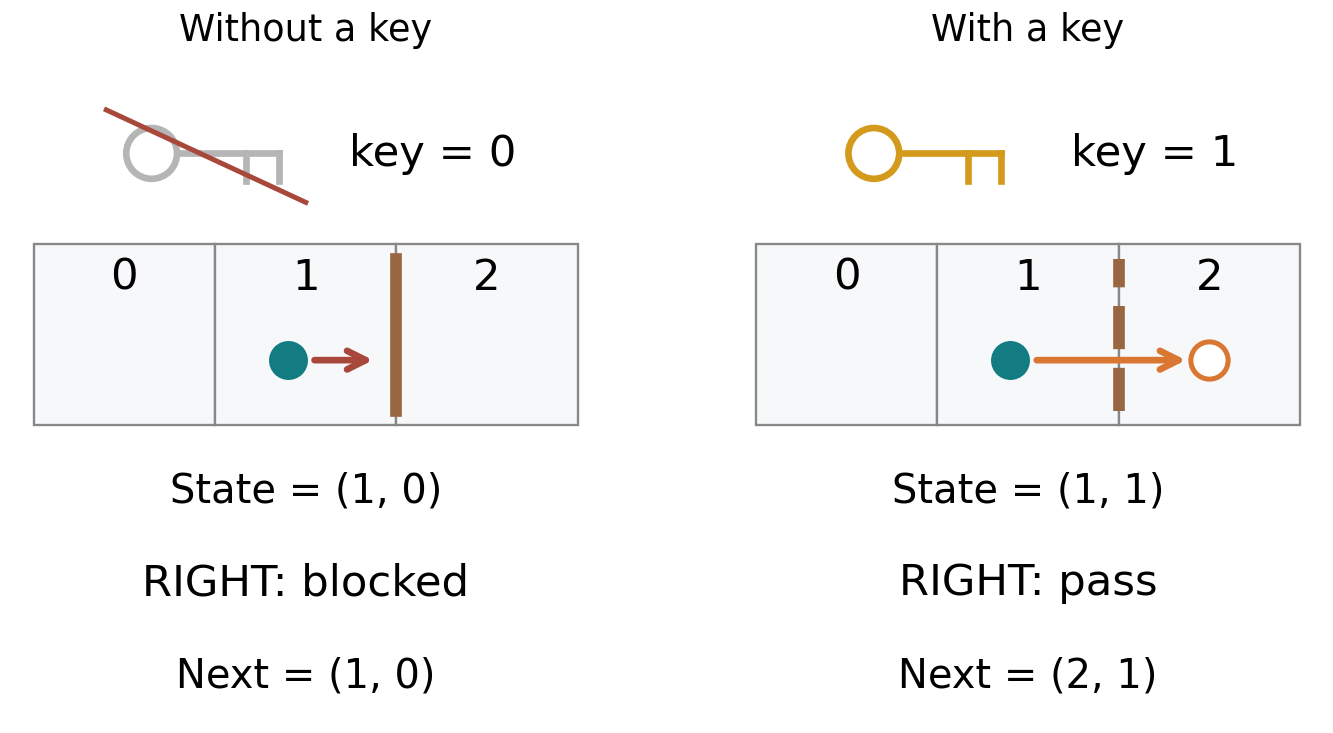

In [15]:
# 同じ「位置 1」でも、鍵を持っているかどうかで次の状態が変わる。
fig, axes = plt.subplots(1, 2, figsize=(12, 6.0), constrained_layout=True)
for ax, has_key in zip(axes, [False, True]):
    key_color = "#d49a1b" if has_key else "#b5b5b5"
    # 鍵の図形：丸い持ち手、軸、先端の歯。
    key_ring = plt.Circle((.65, 1.5), .14, fill=False, color=key_color, lw=4)
    ax.add_patch(key_ring)
    ax.plot([.79, 1.35], [1.5, 1.5], color=key_color, lw=4)
    ax.plot([1.17, 1.17], [1.5, 1.35], color=key_color, lw=4)
    ax.plot([1.35, 1.35], [1.5, 1.35], color=key_color, lw=4)
    if not has_key:
        ax.plot([.4, 1.5], [1.74, 1.23], color="#a8483b", lw=3)
    ax.text(2.2, 1.5, f"key = {int(has_key)}", ha="center", va="center", fontsize=26)
    for position in range(3):
        ax.add_patch(Rectangle((position, 0), 1, 1, facecolor="#f7f8fa",
                               edgecolor="#888888", linewidth=1.4))
        ax.text(position + .5, .82, str(position), ha="center", va="center", fontsize=26)
    # 扉は位置 1 と位置 2 の境界にある。鍵があると開いて通れる。
    ax.plot([2, 2], [.08, .92], color="#986742", lw=7,
            linestyle="--" if has_key else "-")
    ax.scatter([1.4], [.36], s=500, color=COLORS[0], zorder=4)
    if has_key:
        ax.scatter([2.5], [.36], s=500, facecolor="white", edgecolor=COLORS[1],
                   linewidth=3, zorder=3)
        ax.annotate("", xy=(2.39, .36), xytext=(1.53, .36),
                    arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=28,
                                    color=COLORS[1]))
    else:
        ax.annotate("", xy=(1.89, .36), xytext=(1.53, .36),
                    arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=28,
                                    color="#a8483b"))
    result = "pass" if has_key else "blocked"
    destination = 2 if has_key else 1
    ax.text(1.5, -.42, f"State = (1, {int(has_key)})", ha="center", fontsize=24)
    ax.text(1.5, -.93, f"RIGHT: {result}", ha="center", fontsize=26)
    ax.text(1.5, -1.44, f"Next = ({destination}, {int(has_key)})", ha="center", fontsize=24)
    ax.set(title="With a key" if has_key else "Without a key",
           xlim=(-.12, 3.12), ylim=(-1.63, 1.96), aspect="equal")
    ax.axis("off")
plt.show()

図 2：左右とも位置 1 で `RIGHT` を選ぶが、鍵なしでは停止し、鍵ありでは位置 2 へ進む。位置だけでは過去に鍵を拾ったかを区別できないが、`(位置, 鍵の有無)` を状態に含めれば説明できる。この例では鍵は使用しても残る。<strong>観測した情報が、そのまま十分な状態になるとは限らない</strong>。

### 決定的な遷移と、本編の盤面

次状態が $s'=f(s,a)$ に一意に決まる場合も、行き先の確率を 1、他を 0 とすれば $p(s'\mid s,a)$ で表せる。

以降は図 3 の 3 行 × 4 列を使う。状態は `(行, 列)`、左上が `(0,0)` で、行動は上下左右の 4 つである。壁 `(1,1)` と盤面の外へは進めず、その場にとどまる。ゴールは `(0,3)`、負の報酬のマスは `(1,3)` である。

ゴールに着いたら終了する。確率表を全状態で定義するため、関数上はゴールからゴールへとどまるものとする。次のコードは、この盤面と描画用の関数を用意する。

In [16]:
HEIGHT, WIDTH = 3, 4
START, GOAL, WALL, PENALTY = (2, 0), (0, 3), (1, 1), (1, 3)
ACTION_NAMES = ["UP", "DOWN", "LEFT", "RIGHT"]
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]
STATES = [(row, col) for row in range(HEIGHT) for col in range(WIDTH)
          if (row, col) != WALL]
STATE_INDEX = {state: i for i, state in enumerate(STATES)}
ACTIVE_STATES = [state for state in STATES if state != GOAL]

def draw_grid(ax, title, policy=None):
    labels = {START: "Start", GOAL: "Goal / +1", PENALTY: "Penalty / -1"}
    for row in range(HEIGHT):
        for col in range(WIDTH):
            state = (row, col)
            color = ("#777777" if state == WALL else
                     "#ccece6" if state == GOAL else
                     "#f8ddce" if state == PENALTY else "#f7f8fa")
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=color,
                                   edgecolor="#777777", linewidth=1))
            if state == WALL:
                ax.text(col + .5, row + .5, "Wall", ha="center", va="center",
                        color="white", fontsize=24)
                continue
            ax.text(col + .5, row + .15, str(state), ha="center", va="center",
                    fontsize=26, color="#222222")
            if state in labels:
                ax.text(col + .5, row + .83, labels[state], ha="center",
                        va="center", fontsize=22, fontweight="medium")
            if policy is not None and state in policy:
                dy, dx = MOVES[policy[state]]
                ax.annotate("", xy=(col + .5 + .22 * dx, row + .48 + .22 * dy),
                            xytext=(col + .5 - .15 * dx, row + .48 - .15 * dy),
                            arrowprops=dict(arrowstyle="->", lw=4, mutation_scale=30,
                                            color=COLORS[0]))
    ax.set(xlim=(0, WIDTH), ylim=(HEIGHT, 0), aspect="equal", title=title)
    ax.axis("off")

def next_state(state, action):
    if state == GOAL:
        return GOAL
    dy, dx = MOVES[action]
    candidate = (state[0] + dy, state[1] + dx)
    row, col = candidate
    if not (0 <= row < HEIGHT and 0 <= col < WIDTH) or candidate == WALL:
        return state
    return candidate

SIDE_ACTIONS = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}

def transition_probs(state, action, slip=0.0):
    if not 0 <= slip <= 1:
        raise ValueError("slip must be between 0 and 1")
    probs = np.zeros(len(STATES))
    side1, side2 = SIDE_ACTIONS[action]
    for direction, probability in [(action, 1 - slip),
                                   (side1, slip / 2), (side2, slip / 2)]:
        destination = next_state(state, direction)
        probs[STATE_INDEX[destination]] += probability  # 同じ行き先の確率を合算
    return probs

# どの状態・行動でも、次状態についての確率の和は 1。
for slip in [0.0, 0.2, 1.0]:
    for state in STATES:
        for action in range(4):
            probs = transition_probs(state, action, slip)
            assert np.all(probs >= 0) and np.isclose(probs.sum(), 1)

### 確率的な状態遷移

床が滑る例では、意図した方向へ進む確率を $0.8$、直交する 2 方向へずれる確率をそれぞれ $0.1$ とする。`slip=0.2` は、ずれる確率の合計を表す。`slip=0` なら決定的な移動になる。

壁や盤面の外へ向かう場合は、現在位置に戻す。<strong>複数の方向が同じ次状態になる場合、その確率を足し合わせる</strong>。

図 3 は青緑の枠が現在位置、ループがその場にとどまる遷移である。マス内の `p=...` は次状態の確率、右上の $+1$ と右中央の $-1$ は報酬を表す。

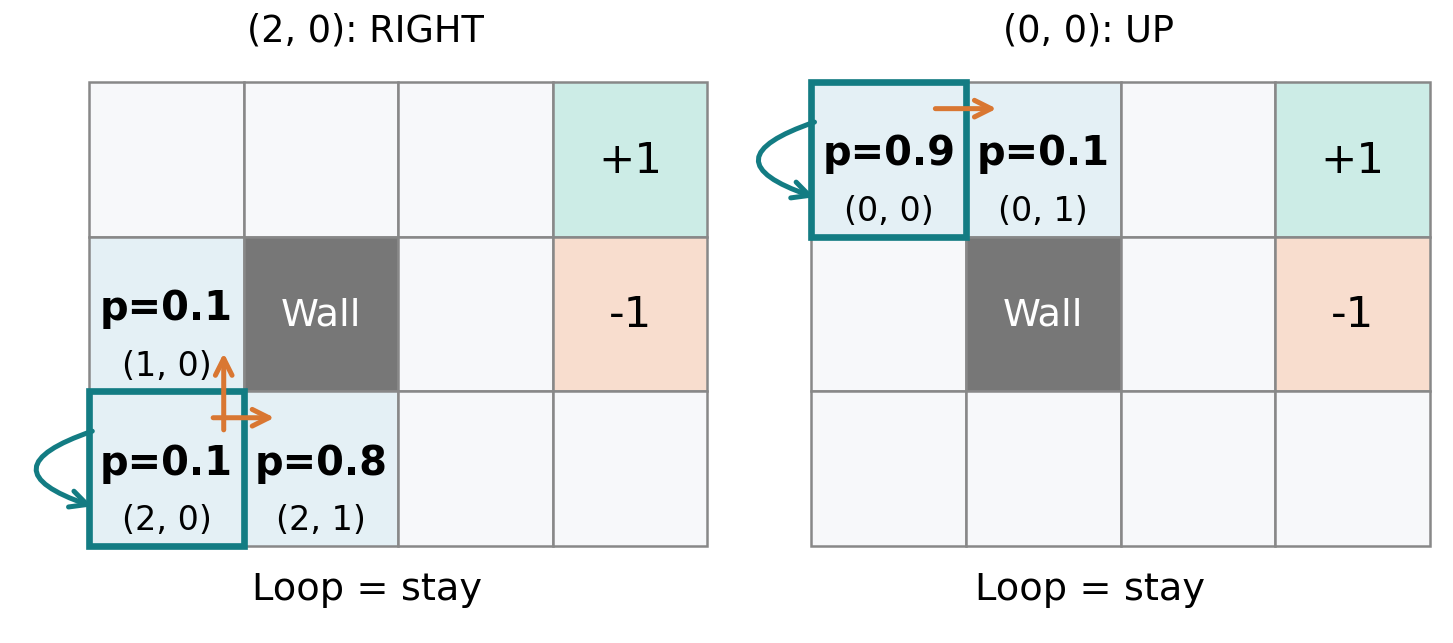

In [17]:
# 2 つの状態・行動を、実際のマスの配置で確かめる。
def draw_stochastic_map(ax, state, action, slip=0.2):
    probabilities = transition_probs(state, action, slip=slip)
    for row in range(HEIGHT):
        for col in range(WIDTH):
            position = (row, col)
            probability = (0.0 if position == WALL else
                           probabilities[STATE_INDEX[position]])
            color = ("#777777" if position == WALL else
                     "#ccece6" if position == GOAL else
                     "#f8ddce" if position == PENALTY else
                     "#e4f0f5" if probability > 0 else "#f7f8fa")
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=color,
                                   edgecolor="#888888", linewidth=1.5))
            if position == WALL:
                ax.text(col + .5, row + .5, "Wall", ha="center", va="center",
                        fontsize=23, color="white")
            elif probability > 0:
                ax.text(col + .5, row + .46, f"p={probability:.1f}",
                        ha="center", va="center", fontsize=24, fontweight="bold")
                ax.text(col + .5, row + .83, str(position),
                        ha="center", va="center", fontsize=20)
            elif position in [GOAL, PENALTY]:
                ax.text(col + .5, row + .5, "+1" if position == GOAL else "-1",
                        ha="center", va="center", fontsize=26)

    row, col = state
    # 太い枠が、行動を選ぶ前の現在位置。
    ax.add_patch(Rectangle((col, row), 1, 1, fill=False,
                           edgecolor=COLORS[0], linewidth=4, zorder=5))
    for i in np.flatnonzero(probabilities):
        destination = STATES[i]
        if destination == state:
            # 現在位置へ戻る矢印を、盤面の左側へ膨らませて描く。
            ax.annotate("", xy=(col + .04, row + .75),
                        xytext=(col + .04, row + .25),
                        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=1.5",
                                        lw=3, mutation_scale=25, color=COLORS[0]), zorder=6)
        elif destination[0] == row:  # 右へ移る枝
            ax.annotate("", xy=(destination[1] + .22, row + .17),
                        xytext=(col + .78, row + .17),
                        arrowprops=dict(arrowstyle="->", lw=3,
                                        mutation_scale=25, color=COLORS[1]), zorder=6)
        else:  # 上へ移る枝（数値や座標に重ならないよう、マスの右寄りに描く）
            ax.annotate("", xy=(col + .87, destination[0] + .73),
                        xytext=(col + .87, row + .27),
                        arrowprops=dict(arrowstyle="->", lw=3,
                                        mutation_scale=25, color=COLORS[1]), zorder=6)
    ax.text(1.8, 3.28, "Loop = stay", ha="center", va="center", fontsize=23)
    ax.set(title=f"{state}: {ACTION_NAMES[action]}", xlim=(-.5, WIDTH + .08),
           ylim=(3.55, -.08), aspect="equal")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), constrained_layout=True)
for ax, (state, action) in zip(axes, [(START, 3), ((0, 0), 0)]):
    draw_stochastic_map(ax, state, action, slip=0.2)
plt.show()

図 3：左の `(2,0)` で `RIGHT` を選ぶと、右の `(2,1)` へ $0.8$、上の `(1,0)` へ $0.1$、その場へ $0.1$ となる。下へのずれは盤面の外に向かうため、移動しない。

右の `(0,0)` で `UP` を選ぶと、上への $0.8$ と左への $0.1$ が合算され、その場にとどまる確率は $0.9$。右へ進む確率は $0.1$ になる。各例の確率の合計は 1 である。矢印は移動を試みる方向ではなく、実際の次状態を示す。

## 2.2.2 報酬関数

状態 $s$ から行動 $a$ によって $s'$ へ移ったときの報酬を $r(s,a,s')$ と書く。今回のグリッドでは、実際の移動先で決める。

$$r(s,a,s')=\begin{cases}
0 & (s=\mathrm{Goal}),\\
+1 & (s\ne\mathrm{Goal},\ s'=\mathrm{Goal}),\\
-1 & (s\ne\mathrm{Goal},\ s'=\mathrm{Penalty}),\\
0 & (\text{それ以外}).
\end{cases}$$

ゴールに入るときだけ $+1$ を得て終了し、その後の報酬は 0 とする。Penalty は終了マスではない。そこで壁へ向かってとどまった場合も、移動先が Penalty なので $-1$ を得る。

一般には報酬が移動元や行動にも依存してよい。たとえば、燃料を多く使う行動に負の報酬を設定できる。ここでは遷移が決まれば報酬も決まるものとする。

### 次状態が確率的なときの期待報酬

状態 $s$ と行動 $a$ を固定し、次状態ごとの報酬を確率で重み付けする。

$$\bar r(s,a)=\mathbb E[R_t\mid S_t=s,A_t=a]
=\sum_{s'}p(s'\mid s,a)\,r(s,a,s').$$

$\bar r(s,a)$ は次状態について平均した値であり、遷移ごとの報酬関数とは区別する。図 4 ではゴール左の `(0,2)` から `RIGHT` を選ぶ。床が滑るので、必ずゴールへ入れるわけではない。

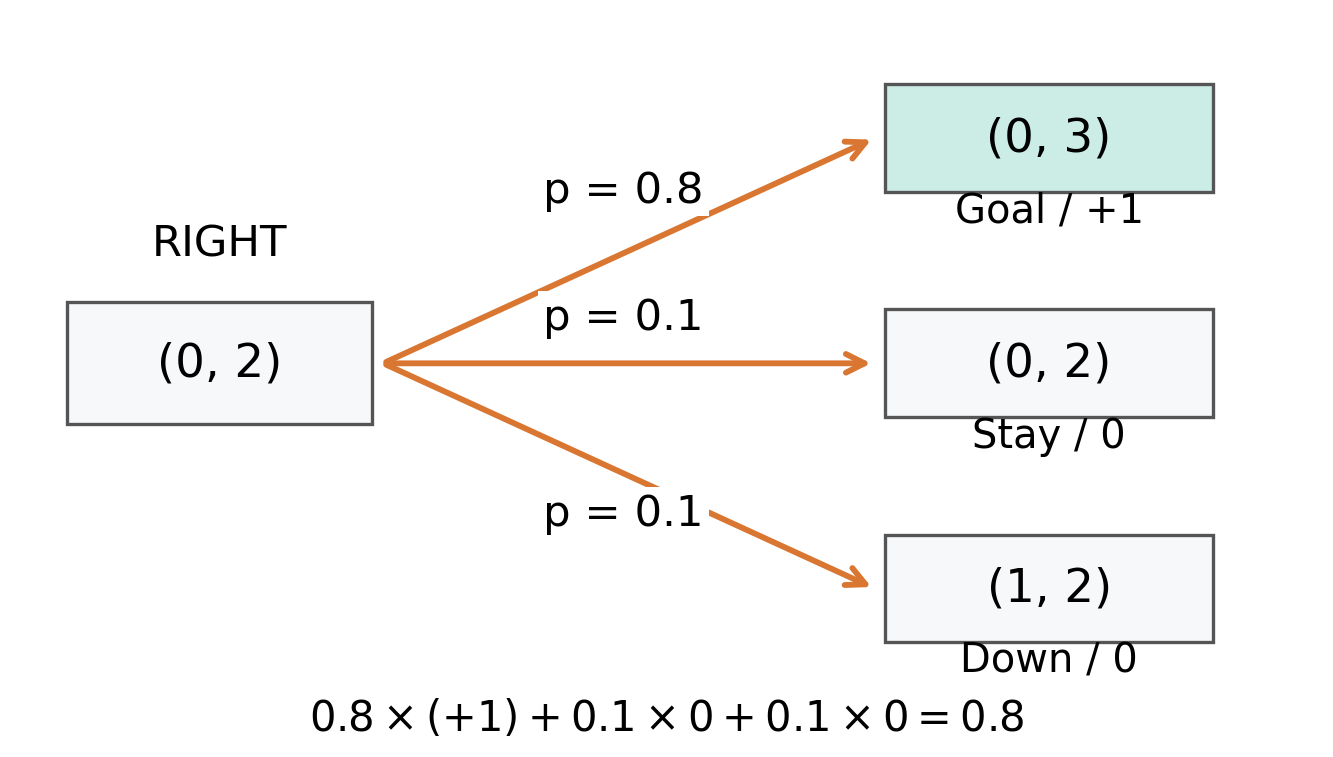

In [18]:
def reward(state, action, s_next):
    if state == GOAL:
        return 0.0
    if s_next == GOAL:
        return 1.0
    if s_next == PENALTY:
        return -1.0
    return 0.0

reward_source = (0, 2)
reward_action = 3
branch_probs = transition_probs(reward_source, reward_action, slip=0.2)
fig, ax = plt.subplots(figsize=(11, 6.2), constrained_layout=True)
ax.set(xlim=(0, 12), ylim=(-.8, 6.7))
ax.axis("off")
concept_box(ax, (1.9, 3.1), str(reward_source), width=2.8, height=1.25, fontsize=28)
ax.text(1.9, 4.2, "RIGHT", ha="center", fontsize=26)
outcomes = [(GOAL, 5.4, "Goal"), (reward_source, 3.1, "Stay"), ((1, 2), .8, "Down")]
for destination, y, name in outcomes:
    probability = branch_probs[STATE_INDEX[destination]]
    r_t = reward(reward_source, reward_action, destination)
    concept_arrow(ax, (3.4, 3.1), (7.9, y), color=COLORS[1])
    label_y = {5.4: 4.75, 3.1: 3.45, .8: 1.45}[y]
    ax.text(5.6, label_y, f"p = {probability:.1f}", ha="center", fontsize=26,
            bbox=dict(facecolor="white", edgecolor="none", pad=3))
    concept_box(ax, (9.5, y), str(destination), width=3, height=1.1,
                color="#ccece6" if destination == GOAL else "#f7f8fa", fontsize=28)
    r_label = "+1" if r_t == 1 else "0"
    ax.text(9.5, y - .85, f"{name} / {r_label}", ha="center", fontsize=24)
ax.text(6, -.65, r"$0.8\times(+1)+0.1\times0+0.1\times0=0.8$",
        ha="center", fontsize=25)
plt.show()

図 4：ゴールへ進む確率 $0.8$ のときだけ報酬 $+1$。上へずれてとどまる場合と、下の `(1,2)` へ進む場合は、それぞれ確率 $0.1$ で報酬 0 となる。したがって期待報酬は $0.8$ である。

<strong>1 回に報酬 $0.8$ が返るのではない</strong>。この例で観測する報酬は 0 または 1 である。また、この期待値に次の時刻以降の報酬はまだ含まれていない。

## 2.2.3 エージェントの方策

状態に応じて行動を選ぶ規則を<strong>方策（policy）</strong>という。決定的方策では $a=\mu(s)$ と行動が 1 つに決まり、確率的方策では行動の確率を与える。

$$\pi(a\mid s)=P(A_t=a\mid S_t=s),\qquad
\pi(a\mid s)\ge0,\quad\sum_{a\in\mathcal A}\pi(a\mid s)=1.$$

こちらは状態 $s$ を固定し、<strong>行動 $a$</strong>について和を取る。状態遷移確率が「次状態について合計 1」だったことと区別する。

決定的方策も、選ぶ行動の確率を 1、他を 0 とすれば $\pi$ で表せる。図 5 では、手で決めた方策、一様ランダム方策、優先行動を選びやすくした方策を比べる。いずれも状態ごとに同じ規則を使い続ける。

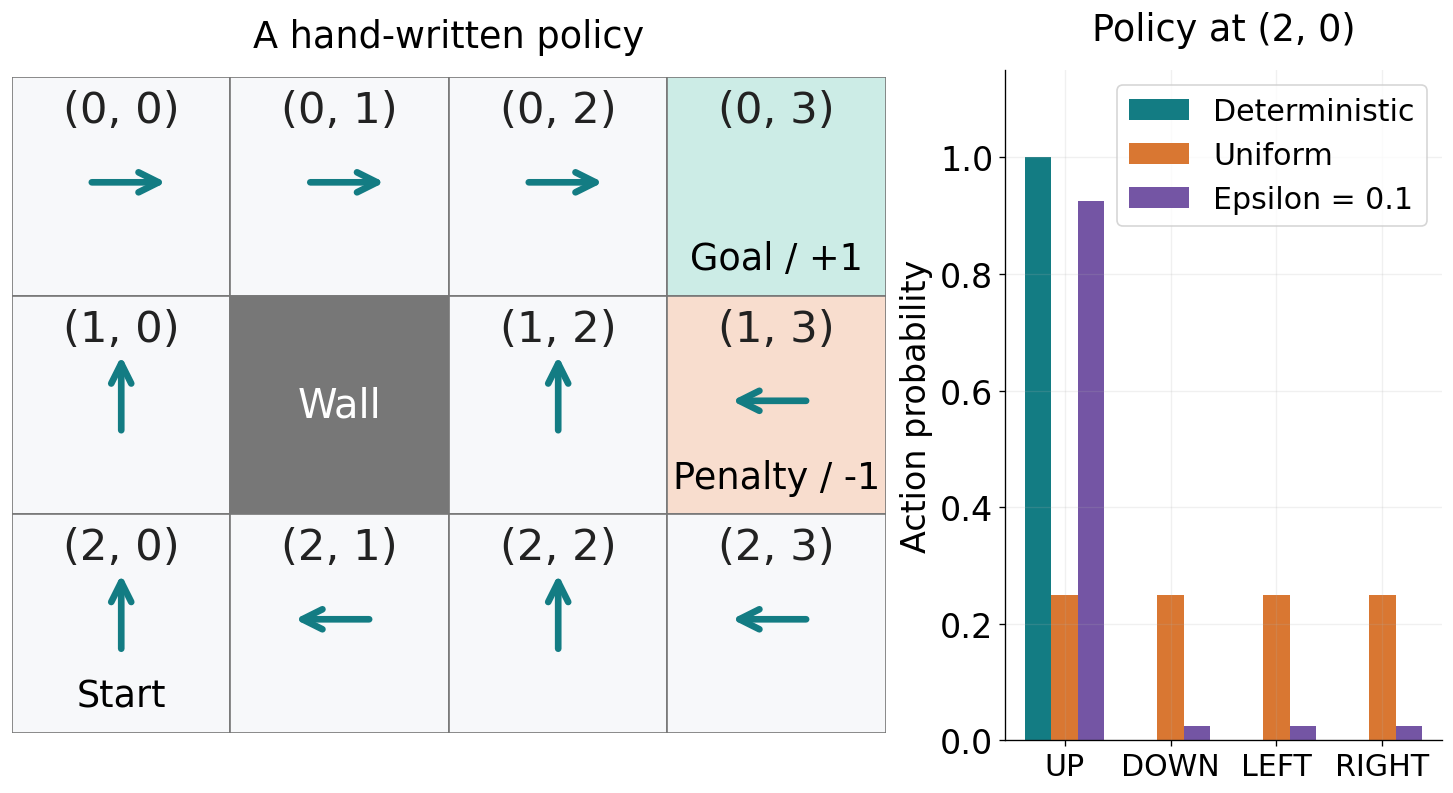

In [19]:
# 説明用に人が決めた方策。ゴールでは行動を選ばない。
chosen_actions = {
    (0, 0): 3, (0, 1): 3, (0, 2): 3,
    (1, 0): 0,            (1, 2): 0, (1, 3): 2,
    (2, 0): 0, (2, 1): 2, (2, 2): 0, (2, 3): 2,
}
pi_deterministic = {s: np.eye(4)[chosen_actions[s]] for s in ACTIVE_STATES}
pi_uniform = {s: np.full(4, 0.25) for s in ACTIVE_STATES}

epsilon = 0.1
pi_epsilon = {}
for state in ACTIVE_STATES:
    probabilities = np.full(4, epsilon / 4)
    probabilities[chosen_actions[state]] += 1 - epsilon
    pi_epsilon[state] = probabilities

for policy in [pi_deterministic, pi_uniform, pi_epsilon]:
    assert set(policy) == set(ACTIVE_STATES)
    for probabilities in policy.values():
        assert np.all(probabilities >= 0) and np.isclose(probabilities.sum(), 1)

# 横並びのまま、長いラベルを含むグリッド側に幅を確保する。
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2, 1]})
draw_grid(axes[0], "A hand-written policy", chosen_actions)
x = np.arange(4)
for offset, (name, policy) in zip([-.25, 0, .25], [
    ("Deterministic", pi_deterministic), ("Uniform", pi_uniform),
    ("Epsilon = 0.1", pi_epsilon),
]):
    axes[1].bar(x + offset, policy[START], width=.25, label=name)
axes[1].set(xticks=x, xticklabels=ACTION_NAMES, ylim=(0, 1.15),
            ylabel="Action probability", title=f"Policy at {START}")
axes[1].tick_params(axis="x", labelsize=18)
axes[1].legend(loc="upper right", fontsize=18)
plt.show()

図 5：左の矢印は手で決めた行動であり、学習結果ではない。右はスタートでの行動確率で、決定的方策では `UP` が 1、一様ランダム方策では各行動が $0.25$ になる。

探索で全 4 行動から等確率に選ぶ場合、優先行動の確率は $1-\varepsilon+\varepsilon/4$、他はそれぞれ $\varepsilon/4$。$\varepsilon=0.1$ なら $0.925$ と $0.025$ になる。探索でも優先行動を選ぶため、$0.9$ ではない。ここでは価値の推定や方策の更新は行っていない。

### 方策の確率と、環境の確率を分ける

必ず同じ行動を選ぶ方策でも、床が滑れば次状態は変わる。反対に、床が滑らなくても、方策がランダムなら行動が変わる。

図 6 は `(0,2)` で `RIGHT` を優先する場合である。青緑の枝で<strong>方策が行動を選び</strong>、その後、橙の枝で<strong>環境が次状態を返す</strong>。この順序を保って考える。

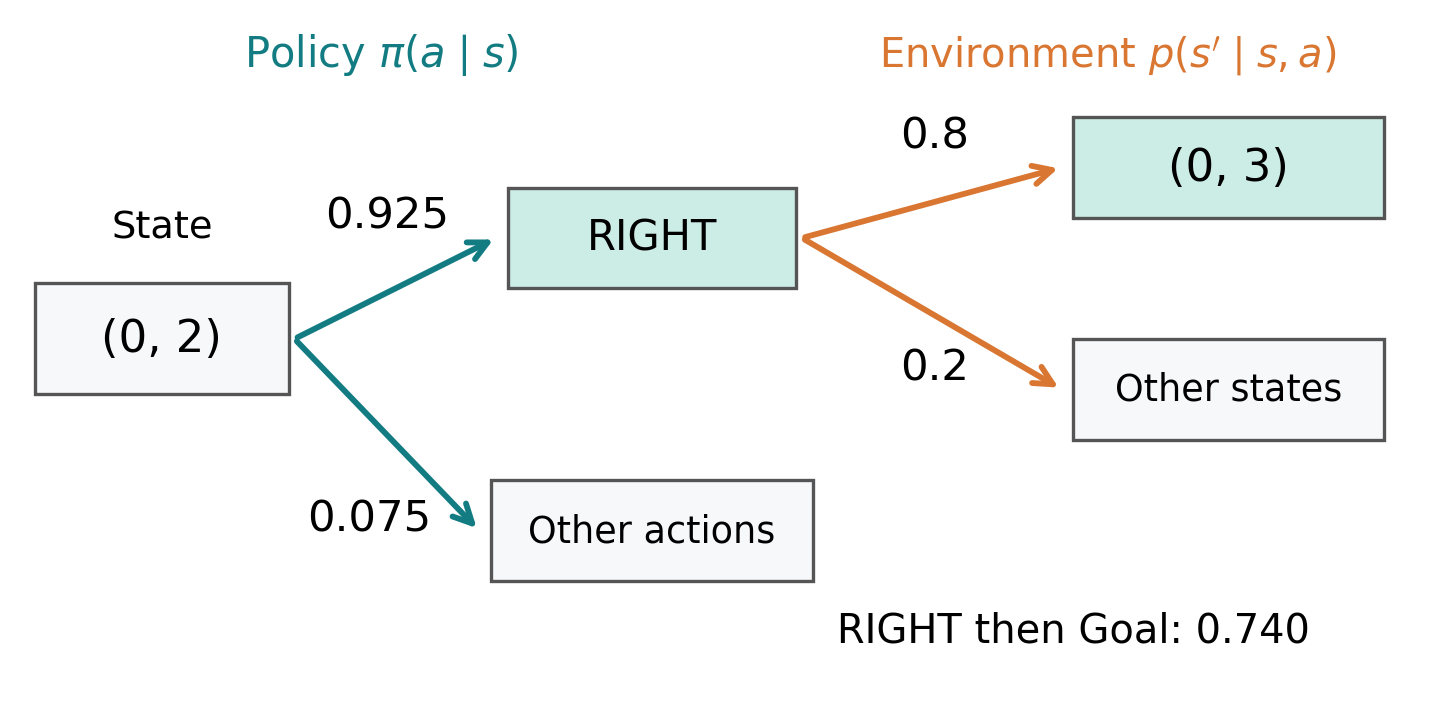

In [20]:
choice_state = (0, 2)
right_probability = pi_epsilon[choice_state][3]
goal_given_right = transition_probs(choice_state, 3, slip=0.2)[STATE_INDEX[GOAL]]
fig, ax = plt.subplots(figsize=(12, 5.8), constrained_layout=True)
ax.set(xlim=(0, 12.4), ylim=(0, 6.8))
ax.axis("off")
ax.text(3.2, 6.25, r"Policy $\pi(a\mid s)$", ha="center", fontsize=25, color=COLORS[0])
ax.text(9.5, 6.25, r"Environment $p(s'\mid s,a)$", ha="center", fontsize=24, color=COLORS[1])
concept_box(ax, (1.3, 3.55), str(choice_state), width=2.2, height=1.1, fontsize=27)
ax.text(1.3, 4.55, "State", ha="center", fontsize=23)
concept_box(ax, (5.55, 4.55), "RIGHT", width=2.5, height=1.0, color="#ccece6", fontsize=25)
concept_box(ax, (5.55, 1.65), "Other actions", width=2.8, height=1.0, fontsize=22)
concept_box(ax, (10.55, 5.25), str(GOAL), width=2.7, height=1.0, color="#ccece6", fontsize=27)
concept_box(ax, (10.55, 3.05), "Other states", width=2.7, height=1.0, fontsize=22)
concept_arrow(ax, (2.45, 3.55), (4.2, 4.55))
concept_arrow(ax, (2.45, 3.55), (4.05, 1.65))
ax.text(3.25, 4.65, f"{right_probability:.3f}", ha="center", fontsize=26)
ax.text(3.1, 1.65, f"{1-right_probability:.3f}", ha="center", fontsize=26)
concept_arrow(ax, (6.85, 4.55), (9.1, 5.25), color=COLORS[1])
concept_arrow(ax, (6.85, 4.55), (9.1, 3.05), color=COLORS[1])
ax.text(8, 5.45, f"{goal_given_right:.1f}", ha="center", fontsize=26)
ax.text(8, 3.15, f"{1-goal_given_right:.1f}", ha="center", fontsize=26)
ax.text(9.2, .55, f"RIGHT then Goal: {right_probability * goal_given_right:.3f}",
        ha="center", fontsize=24)
plt.show()

図 6：`RIGHT` を選ぶ確率は $0.925$、選んだ条件でゴールに移る確率は $0.8$。両方が起きる確率は $0.925\times0.8=0.740$ である。

$$P(A_t=a,S_{t+1}=s'\mid S_t=s)=\pi(a\mid s)\,p(s'\mid s,a).$$

これは行動と次状態が独立だから掛けるのではなく、選んだ行動を条件に次状態が決まるためである。他の行動からゴールへ着く場合は含めていない。図では他の行動の確率を合計 $0.075$ とし、その先の分岐は省略している。

## 2.1〜2.2 のまとめ

| 確認したいこと | 使うもの | 確率の和を取る対象 |
|---|---|---|
| 次にどこへ移るか | $p(s'\mid s,a)$ | 固定した $(s,a)$ ごとに次状態 $s'$ |
| 遷移で何点を得るか | $r(s,a,s')$ | 確率ではないので合計 1 の条件はない |
| どの行動を選ぶか | $\pi(a\mid s)$ | 固定した状態 $s$ ごとに行動 $a$ |

マルコフ性は、現在の状態と行動で次の結果の分布を説明できること。環境と方策の不確実さ、1 回の報酬とその期待値を区別する。次の 2.3 では、将来の報酬をどうまとめ、状態や方策のよさを測るかを考える。

## 確認問題

1. 図 3 の右で、同じ場所にとどまる確率が $0.9$ になるのはなぜか。確率的に移動してもマルコフ性は満たせるか。
2. 図 4 の期待報酬と、1 回に観測する報酬を答えよ。
3. 4 行動のうち優先行動が 1 つあるとき、$\varepsilon=0.2$ で各行動を選ぶ確率はいくつか。この確率と状態遷移確率は何が違うか。

<details>
<summary>解答例（クリックして開く）</summary>

1. 上への $0.8$ と左への $0.1$ がどちらも盤面の外に向かうため、$0.9$ になる。過去の経路によらず、現在の状態と行動から同じ分布になるならマルコフ性を満たす。
2. 期待報酬は $0.8\times1+0.1\times0+0.1\times0=0.8$。1 回の報酬は、ゴールに着けば 1、それ以外は 0 である。
3. 優先行動は $1-0.2+0.2/4=0.85$、他の 3 行動はそれぞれ $0.05$。方策は「どの行動を選ぶか」、状態遷移確率は「その行動を選んだ後、どこへ移るか」を表す。

</details>